# Task 03: Features and Hyperparameter Tuning

## Student Placement Prediction

### Objective
To improve the Student Placement Prediction model using:
1. Feature Engineering
2. Cross Validation
3. Hyperparameter Tuning
4. Before and After Model Comparison

In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [3]:
df = pd.read_csv("data/Placement_Data_Full_Class.csv")

print(df.head())

   sl_no gender  ssc_p    ssc_b  hsc_p    hsc_b     hsc_s  degree_p  \
0      1      M  67.00   Others  91.00   Others  Commerce     58.00   
1      2      M  79.33  Central  78.33   Others   Science     77.48   
2      3      M  65.00  Central  68.00  Central      Arts     64.00   
3      4      M  56.00  Central  52.00  Central   Science     52.00   
4      5      M  85.80  Central  73.60  Central  Commerce     73.30   

    degree_t workex  etest_p specialisation  mba_p      status    salary  
0   Sci&Tech     No     55.0         Mkt&HR  58.80      Placed  270000.0  
1   Sci&Tech    Yes     86.5        Mkt&Fin  66.28      Placed  200000.0  
2  Comm&Mgmt     No     75.0        Mkt&Fin  57.80      Placed  250000.0  
3   Sci&Tech     No     66.0         Mkt&HR  59.43  Not Placed       NaN  
4  Comm&Mgmt     No     96.8        Mkt&Fin  55.50      Placed  425000.0  


In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (215, 15)


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 215 entries, 0 to 214
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   sl_no           215 non-null    int64  
 1   gender          215 non-null    str    
 2   ssc_p           215 non-null    float64
 3   ssc_b           215 non-null    str    
 4   hsc_p           215 non-null    float64
 5   hsc_b           215 non-null    str    
 6   hsc_s           215 non-null    str    
 7   degree_p        215 non-null    float64
 8   degree_t        215 non-null    str    
 9   workex          215 non-null    str    
 10  etest_p         215 non-null    float64
 11  specialisation  215 non-null    str    
 12  mba_p           215 non-null    float64
 13  status          215 non-null    str    
 14  salary          148 non-null    float64
dtypes: float64(6), int64(1), str(8)
memory usage: 25.3 KB


In [6]:
print(df.isnull().sum())

sl_no              0
gender             0
ssc_p              0
ssc_b              0
hsc_p              0
hsc_b              0
hsc_s              0
degree_p           0
degree_t           0
workex             0
etest_p            0
specialisation     0
mba_p              0
status             0
salary            67
dtype: int64


In [7]:
print(df["status"].value_counts())

status
Placed        148
Not Placed     67
Name: count, dtype: int64


In [8]:
df.describe()

,sl_no,ssc_p,hsc_p,degree_p,etest_p,mba_p,salary
count,215.000000,215.000000,215.000000,215.000000,215.000000,215.000000,148.000000
mean,108.000000,67.303395,66.333163,66.370186,72.100558,62.278186,288655.405405
std,62.209324,10.827205,10.897509,7.358743,13.275956,5.833385,93457.452420
min,1.000000,40.890000,37.000000,50.000000,50.000000,51.210000,200000.000000
25%,54.500000,60.600000,60.900000,61.000000,60.000000,57.945000,240000.000000
50%,108.000000,67.000000,65.000000,66.000000,71.000000,62.000000,265000.000000
75%,161.500000,75.700000,73.000000,72.000000,83.500000,66.255000,300000.000000
max,215.000000,89.400000,97.700000,91.000000,98.000000,77.890000,940000.000000


In [9]:
# Remove unnecessary columns

df = df.drop(["sl_no", "salary"], axis=1)

print(df.head())
print("New Shape:", df.shape)

  gender  ssc_p    ssc_b  hsc_p    hsc_b     hsc_s  degree_p   degree_t  \
0      M  67.00   Others  91.00   Others  Commerce     58.00   Sci&Tech   
1      M  79.33  Central  78.33   Others   Science     77.48   Sci&Tech   
2      M  65.00  Central  68.00  Central      Arts     64.00  Comm&Mgmt   
3      M  56.00  Central  52.00  Central   Science     52.00   Sci&Tech   
4      M  85.80  Central  73.60  Central  Commerce     73.30  Comm&Mgmt   

  workex  etest_p specialisation  mba_p      status  
0     No     55.0         Mkt&HR  58.80      Placed  
1    Yes     86.5        Mkt&Fin  66.28      Placed  
2     No     75.0        Mkt&Fin  57.80      Placed  
3     No     66.0         Mkt&HR  59.43  Not Placed  
4     No     96.8        Mkt&Fin  55.50      Placed  
New Shape: (215, 13)


In [10]:
X = df.drop("status", axis=1)

y = df["status"]

print("X Shape:", X.shape)
print("y Shape:", y.shape)

X Shape: (215, 12)
y Shape: (215,)


In [11]:
X["academic_average"] = (
    X["ssc_p"] + X["hsc_p"] + X["degree_p"]
) / 3

X["skill_average"] = (
    X["etest_p"] + X["mba_p"]
) / 2

X["academic_improvement"] = (
    X["degree_p"] - X["ssc_p"]
)

print(X.head())

  gender  ssc_p    ssc_b  hsc_p    hsc_b     hsc_s  degree_p   degree_t  \
0      M  67.00   Others  91.00   Others  Commerce     58.00   Sci&Tech   
1      M  79.33  Central  78.33   Others   Science     77.48   Sci&Tech   
2      M  65.00  Central  68.00  Central      Arts     64.00  Comm&Mgmt   
3      M  56.00  Central  52.00  Central   Science     52.00   Sci&Tech   
4      M  85.80  Central  73.60  Central  Commerce     73.30  Comm&Mgmt   

  workex  etest_p specialisation  mba_p  academic_average  skill_average  \
0     No     55.0         Mkt&HR  58.80         72.000000         56.900   
1    Yes     86.5        Mkt&Fin  66.28         78.380000         76.390   
2     No     75.0        Mkt&Fin  57.80         65.666667         66.400   
3     No     66.0         Mkt&HR  59.43         53.333333         62.715   
4     No     96.8        Mkt&Fin  55.50         77.566667         76.150   

   academic_improvement  
0                 -9.00  
1                 -1.85  
2             

In [12]:
print("Original features:", 12)
print("New features:", 3)
print("Total features:", X.shape[1])

print(X.head())

Original features: 12
New features: 3
Total features: 15
  gender  ssc_p    ssc_b  hsc_p    hsc_b     hsc_s  degree_p   degree_t  \
0      M  67.00   Others  91.00   Others  Commerce     58.00   Sci&Tech   
1      M  79.33  Central  78.33   Others   Science     77.48   Sci&Tech   
2      M  65.00  Central  68.00  Central      Arts     64.00  Comm&Mgmt   
3      M  56.00  Central  52.00  Central   Science     52.00   Sci&Tech   
4      M  85.80  Central  73.60  Central  Commerce     73.30  Comm&Mgmt   

  workex  etest_p specialisation  mba_p  academic_average  skill_average  \
0     No     55.0         Mkt&HR  58.80         72.000000         56.900   
1    Yes     86.5        Mkt&Fin  66.28         78.380000         76.390   
2     No     75.0        Mkt&Fin  57.80         65.666667         66.400   
3     No     66.0         Mkt&HR  59.43         53.333333         62.715   
4     No     96.8        Mkt&Fin  55.50         77.566667         76.150   

   academic_improvement  
0        

In [13]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

print("Numerical Features:")
print(list(numeric_features))

print("\nCategorical Features:")
print(list(categorical_features))

Numerical Features:
['ssc_p', 'hsc_p', 'degree_p', 'etest_p', 'mba_p', 'academic_average', 'skill_average', 'academic_improvement']

Categorical Features:
['gender', 'ssc_b', 'hsc_b', 'hsc_s', 'degree_t', 'workex', 'specialisation']


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_2732\3313847304.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [14]:
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [15]:
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [16]:
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [17]:
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [41]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [46]:
scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, pos_label="Placed"),
    "recall": make_scorer(recall_score, pos_label="Placed"),
    "f1": make_scorer(f1_score, pos_label="Placed")
}

baseline_scores = cross_validate(
    baseline_model,
    X,
    y,
    cv=cv,
    scoring=scoring 
)

In [47]:
print("BASELINE MODEL RESULTS")

for metric in scoring:
    score = baseline_scores["test_" + metric].mean()

    print(metric, ":", round(score, 4))

BASELINE MODEL RESULTS
accuracy : 0.8744
precision : 0.8914
recall : 0.9324
f1 : 0.911


In [48]:
baseline_results = {}

for metric in scoring:
    baseline_results[metric] = (
        baseline_scores["test_" + metric].mean()
    )

print(baseline_results)

{'accuracy': np.float64(0.8744186046511627), 'precision': np.float64(0.8914367816091954), 'recall': np.float64(0.9324137931034482), 'f1': np.float64(0.9109985748729486)}


In [49]:
tuned_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

In [50]:
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["liblinear", "lbfgs"],
    "classifier__class_weight": [None, "balanced"]
}

In [51]:
from sklearn.metrics import make_scorer, f1_score
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": make_scorer(
        f1_score,
        pos_label="Placed"
    )
}
grid_search = GridSearchCV(
    estimator=tuned_model,
    param_grid=param_grid,
    cv=cv,
    scoring=scoring,
    refit="f1",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X, y)

Fitting 5 folds for each of 20 candidates, totalling 100 fits


c:\Users\Lenovo\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\model_selection\_search.py:1237: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan]
  warnings.warn(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.01, 0.1, ...], 'classifier__class_weight': [None, 'balanced'], 'classifier__solver': ['liblinear', 'lbfgs']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'accuracy': 'accuracy', 'f1': make_scorer(f..._label=Placed), 'precision': 'precision', 'recall': 'recall'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that c

In [52]:
print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation F1 Score:")
print(grid_search.best_score_)

Best Parameters:
{'classifier__C': 0.1, 'classifier__class_weight': None, 'classifier__solver': 'liblinear'}

Best Cross Validation F1 Score:
0.9145284681826193


In [64]:
from sklearn.metrics import make_scorer
from sklearn.metrics import precision_score, recall_score, f1_score

new_scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score,
        pos_label="Placed",
        zero_division=0
    ),
    "recall": make_scorer(
        recall_score,
        pos_label="Placed",
        zero_division=0
    ),
    "f1": make_scorer(
        f1_score,
        pos_label="Placed",
        zero_division=0
    )
}

In [67]:
from sklearn.metrics import make_scorer, f1_score

f1_scorer = make_scorer(
    f1_score,
    pos_label="Placed"
)

nested_search = GridSearchCV(
    estimator=tuned_model,
    param_grid=param_grid,
    cv=5,
    scoring=f1_scorer,
    n_jobs=-1
)

after_scores = cross_validate(
    nested_search,
    X,
    y,
    cv=cv,
    scoring=new_scoring,
    n_jobs=-1,
    
)

In [68]:
after_results = {}

for metric in scoring:
    after_results[metric] = (
        after_scores["test_" + metric].mean()
    )

print("AFTER TUNING RESULTS")

for metric, score in after_results.items():
    print(metric, ":", round(score, 4))

AFTER TUNING RESULTS
accuracy : 0.8744
precision : 0.8912
recall : 0.9326
f1 : 0.9109


In [69]:
comparison = pd.DataFrame({
    "Metric": list(scoring.keys()),
    "Before": [
        baseline_results[m] for m in scoring
    ],
    "After": [
        after_results[m] for m in scoring
    ]
})

comparison["Improvement"] = (
    comparison["After"] - comparison["Before"]
)

print(comparison.round(4))

      Metric  Before   After  Improvement
0   accuracy  0.8744  0.8744       0.0000
1  precision  0.8914  0.8912      -0.0003
2     recall  0.9324  0.9326       0.0002
3         f1  0.9110  0.9109      -0.0001


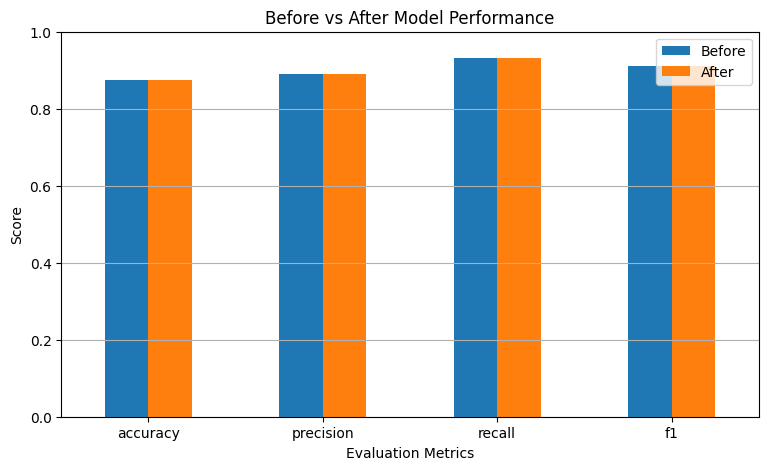

In [70]:
comparison_plot = comparison.set_index("Metric")[
    ["Before", "After"]
]

comparison_plot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Before vs After Model Performance")
plt.ylabel("Score")
plt.xlabel("Evaluation Metrics")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()

In [71]:
from sklearn.metrics import make_scorer
from sklearn.metrics import precision_score, recall_score, f1_score

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score,
        pos_label="Placed",
        zero_division=0
    ),
    "recall": make_scorer(
        recall_score,
        pos_label="Placed",
        zero_division=0
    ),
    "f1": make_scorer(
        f1_score,
        pos_label="Placed",
        zero_division=0
    )
}

print(scoring)

{'accuracy': 'accuracy', 'precision': make_scorer(precision_score, response_method='predict', pos_label=Placed, zero_division=0), 'recall': make_scorer(recall_score, response_method='predict', pos_label=Placed, zero_division=0), 'f1': make_scorer(f1_score, response_method='predict', pos_label=Placed, zero_division=0)}


In [72]:
nested_search = GridSearchCV(
    estimator=tuned_model,
    param_grid=param_grid,
    cv=5,
    scoring=scoring,
    refit="f1",
    n_jobs=-1
)

after_scores = cross_validate(
    nested_search,
    X,
    y,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [73]:
after_results = {}

for metric in scoring:
    after_results[metric] = (
        after_scores["test_" + metric].mean()
    )

print("AFTER TUNING RESULTS")

for metric, score in after_results.items():
    print(metric, ":", round(score, 4))

AFTER TUNING RESULTS
accuracy : 0.8744
precision : 0.8912
recall : 0.9326
f1 : 0.9109


In [74]:
comparison = pd.DataFrame({
    "Metric": list(scoring.keys()),
    "Before": [
        baseline_results[m] for m in scoring
    ],
    "After": [
        after_results[m] for m in scoring
    ]
})

comparison["Improvement"] = (
    comparison["After"] - comparison["Before"]
)

print(comparison.round(4))

      Metric  Before   After  Improvement
0   accuracy  0.8744  0.8744       0.0000
1  precision  0.8914  0.8912      -0.0003
2     recall  0.9324  0.9326       0.0002
3         f1  0.9110  0.9109      -0.0001
